# Module 05 — Resampling Methods

**Applied exercises only** · ISLP, Chapter 5

**Printed textbook pages:** 225–227 (exercise starting pages)  

In [1]:
# Common imports: run this cell once before starting the exercises.
# All data sets come from the ISLP package installed in the project's .venv.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from ISLP import load_data, confusion_table
from ISLP.models import ModelSpec as MS, summarize, poly
from ISLP.models import sklearn_sm
from sklearn.model_selection import train_test_split, cross_validate, LeaveOneOut

rng = np.random.default_rng(1)

---

## Exercise 5 · Applied

**Textbook: printed page 225**

In Chapter 4, we used logistic regression to predict the probability of
default using income and balance on the Default data set. We will
now estimate the test error of this logistic regression model using the
validation set approach. Do not forget to set a random seed before
beginning your analysis.

### Exercise 5(a)

Fit a logistic regression model that uses income and balance to
predict default.

In [2]:
# Exercise 5(a)
Default = load_data("Default")
y_default = (Default["default"] == "Yes").astype(int)
X_ib = MS(["income", "balance"]).fit_transform(Default)
glm_ib = sm.GLM(y_default, X_ib, family=sm.families.Binomial()).fit()
summarize(glm_ib)

,coef,std err,z,P>|z|
intercept,-11.540500,0.435000,-26.544,0.0
income,0.000021,0.000005,4.174,0.0
balance,0.005600,0.000000,24.835,0.0


### Exercise 5(b)

Using the validation set approach, estimate the test error of this
model. In order to do this, you must perform the following steps:
i. Split the sample set into a training set and a validation set.
ii. Fit a multiple logistic regression model using only the training observations.
iii. Obtain a prediction of default status for each individual in
the validation set by computing the posterior probability of
default for that individual, and classifying the individual to
the default category if the posterior probability is greater
than 0.5.
iv. Compute the validation set error, which is the fraction of
the observations in the validation set that are misclassified.

In [3]:
# Exercise 5(b)
def validation_error(predictors, seed):
    train, valid = train_test_split(Default, test_size=0.5, random_state=seed)
    spec = MS(predictors).fit(train)
    X_tr, X_va = spec.transform(train), spec.transform(valid)
    y_tr = (train["default"] == "Yes").astype(int)
    fit = sm.GLM(y_tr, X_tr, family=sm.families.Binomial()).fit()   # step ii
    pred = np.where(fit.predict(X_va) > 0.5, "Yes", "No")          # step iii
    return np.mean(pred != valid["default"])                        # step iv

err_b = validation_error(["income", "balance"], seed=0)  # step i: 50/50 split
print(f"Validation-set error (income + balance, seed 0): {err_b:.4f}")

Validation-set error (income + balance, seed 0): 0.0290


### Exercise 5(c)

Repeat the process in (b) three times, using three different splits
of the observations into a training set and a validation set. Comment on the results obtained.

In [4]:
# Exercise 5(c)
errs_c = {seed: validation_error(["income", "balance"], seed) for seed in [1, 2, 3]}
print(pd.Series(errs_c, name="validation error").round(4).to_string())
print(f"Mean over the three splits: {np.mean(list(errs_c.values())):.4f}")

1    0.0250
2    0.0248
3    0.0248
Mean over the three splits: 0.0249


### Exercise 5(d)

Now consider a logistic regression model that predicts the probability of default using income, balance, and a dummy variable
for student. Estimate the test error for this model using the validation set approach. Comment on whether or not including a
dummy variable for student leads to a reduction in the test error
rate.

In [5]:
# Exercise 5(d)
seeds = range(10)
compare = pd.DataFrame({
    "income + balance": [validation_error(["income", "balance"], s) for s in seeds],
    "income + balance + student": [validation_error(["income", "balance", "student"], s) for s in seeds],
}, index=pd.Index(seeds, name="seed"))
display(compare.round(4))
print(compare.mean().round(4))

,income + balance,income + balance + student
seed,,
0,0.0290,0.0292
1,0.0250,0.0262
2,0.0248,0.0254
3,0.0248,0.0252
4,0.0238,0.0244
5,0.0258,0.0256
6,0.0268,0.0280
7,0.0264,0.0262
8,0.0232,0.0230


income + balance              0.0253
income + balance + student    0.0257
dtype: float64


**Observations / conclusions**

With a 50/50 validation split, the logistic model using `income` + `balance` has a validation error of about 2.3–2.9% depending on the split (2.9%, 2.5%, 2.5%, 2.5% for seeds 0–3). The estimate changes from split to split, which is the main weakness of the validation-set approach.
Adding the `student` dummy does **not** reduce the test error. Averaged over 10 splits, the error is 2.53% without it and 2.57% with it, and the difference between the two models on any one split is smaller than the variation from split to split. For reference, always predicting "No" gives about 3.3% error.

---

## Exercise 6 · Applied

**Textbook: printed page 226**

We continue to consider the use of a logistic regression model to
predict the probability of default using income and balance on the
Default data set. In particular, we will now compute estimates for the
standard errors of the income and balance logistic regression coefficients in two different ways: (1) using the bootstrap, and (2) using the
standard formula for computing the standard errors in the sm.GLM()
function. Do not forget to set a random seed before beginning your
analysis.

### Exercise 6(a)

Using the summarize() and sm.GLM() functions, determine the
estimated standard errors for the coefficients associated with
income and balance in a multiple logistic regression model that
uses both predictors.

In [6]:
# Exercise 6(a)
# Same model as 5(a). summarize() rounds to 3 decimals, so also print the exact SEs.
display(summarize(glm_ib))
print("Formula-based standard errors from sm.GLM:")
print(glm_ib.bse[["income", "balance"]].map(lambda v: f"{v:.4e}").to_string())

,coef,std err,z,P>|z|
intercept,-11.540500,0.435000,-26.544,0.0
income,0.000021,0.000005,4.174,0.0
balance,0.005600,0.000000,24.835,0.0


Formula-based standard errors from sm.GLM:
income     4.9852e-06
balance    2.2738e-04


### Exercise 6(b)

Write a function, boot_fn(), that takes as input the Default data
set as well as an index of the observations, and that outputs
the coefficient estimates for income and balance in the multiple
logistic regression model.

In [7]:
# Exercise 6(b)
def boot_fn(D, idx):
    D_ = D.loc[idx]
    X = MS(["income", "balance"]).fit_transform(D_)
    y = (D_["default"] == "Yes").astype(int)
    return sm.GLM(y, X, family=sm.families.Binomial()).fit().params[["income", "balance"]]

print(boot_fn(Default, Default.index))   # full data reproduces the GLM estimates

income     0.000021
balance    0.005647
dtype: float64


### Exercise 6(c)

Following the bootstrap example in the lab, use your boot_fn()
function to estimate the standard errors of the logistic regression
coefficients for income and balance.

In [8]:
# Exercise 6(c)
def boot_SE(func, D, n=None, B=1000, seed=0):
    rng_b = np.random.default_rng(seed)
    n = n or D.shape[0]
    draws = np.array([func(D, rng_b.choice(D.index, n, replace=True)) for _ in range(B)])
    return draws.std(axis=0)

boot_se = pd.Series(boot_SE(boot_fn, Default, B=1000, seed=0), index=["income", "balance"])
print("Bootstrap standard errors (B = 1000):")
print(boot_se.map(lambda v: f"{v:.4e}").to_string())

Bootstrap standard errors (B = 1000):
income     4.7672e-06
balance    2.3044e-04


### Exercise 6(d)

Comment on the estimated standard errors obtained using the
sm.GLM() function and using the bootstrap.

In [9]:
# Exercise 6(d)
se_compare = pd.DataFrame({"sm.GLM formula SE": glm_ib.bse[["income", "balance"]],
                           "bootstrap SE": boot_se})
se_compare["ratio (boot / formula)"] = se_compare["bootstrap SE"] / se_compare["sm.GLM formula SE"]
se_compare

,sm.GLM formula SE,bootstrap SE,ratio (boot / formula)
income,0.000005,0.000005,0.956262
balance,0.000227,0.000230,1.013431


**Observations / conclusions**

The bootstrap SEs (B = 1000) are very close to the `sm.GLM` formula SEs: about 4.8e-6 vs 5.0e-6 for `income` and 2.30e-4 vs 2.27e-4 for `balance` (ratios 0.96 and 1.01). So the logistic model's assumptions behind the formula-based SEs look reasonable for these data. The bootstrap does not need those assumptions, and it agrees.

---

## Exercise 7 · Applied

**Textbook: printed page 226**

In Sections 5.1.2 and 5.1.3, we saw that the cross_validate() function
can be used in order to compute the LOOCV test error estimate.
Alternatively, one could compute those quantities using just sm.GLM()
and the predict() method of the fitted model within a for loop. You
will now take this approach in order to compute the LOOCV error
for a simple logistic regression model on the Weekly data set. Recall
that in the context of classification problems, the LOOCV error is
given in (5.4).

### Exercise 7(a)

Fit a logistic regression model that predicts Direction using Lag1
and Lag2.

In [10]:
# Exercise 7(a)
Weekly = load_data("Weekly")
y_up = (Weekly["Direction"] == "Up").astype(int)
X_lags = MS(["Lag1", "Lag2"]).fit_transform(Weekly)
glm_7a = sm.GLM(y_up, X_lags, family=sm.families.Binomial()).fit()
summarize(glm_7a)

,coef,std err,z,P>|z|
intercept,0.2212,0.061,3.599,0.000
Lag1,-0.0387,0.026,-1.477,0.140
Lag2,0.0602,0.027,2.270,0.023


### Exercise 7(b)

Fit a logistic regression model that predicts Direction using Lag1
and Lag2 using all but the first observation.

In [11]:
# Exercise 7(b)
glm_7b = sm.GLM(y_up.iloc[1:], X_lags.iloc[1:], family=sm.families.Binomial()).fit()
summarize(glm_7b)

,coef,std err,z,P>|z|
intercept,0.2232,0.061,3.630,0.000
Lag1,-0.0384,0.026,-1.466,0.143
Lag2,0.0608,0.027,2.291,0.022


### Exercise 7(c)

Use the model from (b) to predict the direction of the first observation. You can do this by predicting that the first observation
will go up if P(Direction = "Up"|Lag1, Lag2) > 0.5. Was this
observation correctly classified?

In [12]:
# Exercise 7(c)
p_first = glm_7b.predict(X_lags.iloc[[0]]).iloc[0]
pred_first = "Up" if p_first > 0.5 else "Down"
print(f"P(Up | Lag1, Lag2) for observation 1 = {p_first:.4f} -> predicted {pred_first}")
print(f"True direction: {Weekly['Direction'].iloc[0]}; correctly classified: {pred_first == Weekly['Direction'].iloc[0]}")

P(Up | Lag1, Lag2) for observation 1 = 0.5714 -> predicted Up
True direction: Down; correctly classified: False


### Exercise 7(d)

Write a for loop from i = 1 to i = n, where n is the number of
observations in the data set, that performs each of the following
steps:
i. Fit a logistic regression model using all but the ith observation to predict Direction using Lag1 and Lag2.
ii. Compute the posterior probability of the market moving up
for the ith observation.
iii. Use the posterior probability for the ith observation in order
to predict whether or not the market moves up.
iv. Determine whether or not an error was made in predicting
the direction for the ith observation. If an error was made,
then indicate this as a 1, and otherwise indicate it as a 0.

In [13]:
# Exercise 7(d)
n = Weekly.shape[0]
errors = np.zeros(n, dtype=int)
X_np, y_np = X_lags.to_numpy(), y_up.to_numpy()
for i in range(n):
    mask = np.arange(n) != i
    fit_i = sm.GLM(y_np[mask], X_np[mask], family=sm.families.Binomial()).fit()   # i
    p_i = fit_i.predict(X_np[[i]])[0]                                           # ii
    pred_i = int(p_i > 0.5)                                                     # iii
    errors[i] = int(pred_i != y_np[i])                                          # iv
print(f"Number of LOOCV errors: {errors.sum()} out of {n}")

Number of LOOCV errors: 490 out of 1089


### Exercise 7(e)

Take the average of the n numbers obtained in (d)iv in order to
obtain the LOOCV estimate for the test error. Comment on the
results.

In [14]:
# Exercise 7(e)
loocv_err = errors.mean()
print(f"LOOCV estimate of the test error rate: {loocv_err:.4f}")
print(f"Error rate of always predicting Up: {1 - y_up.mean():.4f}")

LOOCV estimate of the test error rate: 0.4500
Error rate of always predicting Up: 0.4444


**Observations / conclusions**

Without the first week, the `Lag1`/`Lag2` model barely changes. It gives observation 1 P(Up) = 0.571, so predicts Up, but that week was actually Down: misclassified.
The full LOOCV loop makes 490 errors in 1,089 fits, for a **LOOCV test error of 45.0%**. That is slightly *worse* than the 44.4% error of always predicting Up. Even though `Lag2` looked significant in-sample, these two lags have essentially no predictive value.

---

## Exercise 8 · Applied

**Textbook: printed page 227**

We will now perform cross-validation on a simulated data set.

### Exercise 8(a)

Generate a simulated data set as follows:
rng = np.random.default_rng(1)
x = rng.normal(size=100)
y = x - 2 * x**2 + rng.normal(size=100)
In this data set, what is n and what is p? Write out the model
used to generate the data in equation form.

In [15]:
# Exercise 8(a)
rng = np.random.default_rng(1)
x = rng.normal(size=100)
y = x - 2 * x**2 + rng.normal(size=100)
print(f"n = {len(x)} observations, p = 1 predictor (x)")
print("Model: Y = X - 2 X^2 + eps,  eps ~ N(0, 1)")

n = 100 observations, p = 1 predictor (x)
Model: Y = X - 2 X^2 + eps,  eps ~ N(0, 1)


### Exercise 8(b)

Create a scatterplot of X against Y . Comment on what you find.

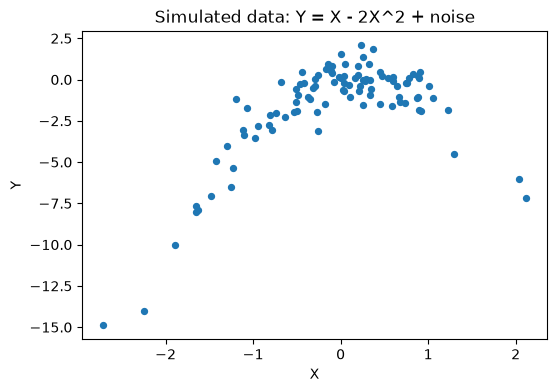

In [16]:
# Exercise 8(b)
fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(x, y, s=18)
ax.set(xlabel="X", ylabel="Y", title="Simulated data: Y = X - 2X^2 + noise")
plt.show()

### Exercise 8(c)

Set a random seed, and then compute the LOOCV errors that
result from fitting the following four models using least squares:
i. Y = β0 + β1X + ϵ
ii. Y = β0 + β1X + β2X2 + ϵ
iii. Y = β0 + β1X + β2X2 + β3X3 + ϵ
iv. Y = β0 + β1X + β2X2 + β3X3 + β4X4 + ϵ.
Note you may find it helpful to use the data.frame() function
to create a single data set containing both X and Y .

In [17]:
# Exercise 8(c)
sim = pd.DataFrame({"x": x, "y": y})

def loocv_poly(data, seed):
    np.random.seed(seed)  # LOOCV has no randomness, but the exercise asks for a seed
    out = {}
    for d in range(1, 5):
        X = MS([poly("x", degree=d, raw=True)]).fit_transform(data)
        model = sklearn_sm(sm.OLS)
        cv = cross_validate(model, X, data["y"], cv=LeaveOneOut(), scoring="neg_mean_squared_error")
        out[d] = -cv["test_score"].mean()
    return pd.Series(out, name=f"LOOCV MSE (seed {seed})")

loocv_c = loocv_poly(sim, seed=1)
loocv_c.index.name = "degree"
loocv_c.round(4)

degree
1    6.6330
2    1.1229
3    1.3018
4    1.3324
Name: LOOCV MSE (seed 1), dtype: float64

### Exercise 8(d)

Repeat (c) using another random seed, and report your results.
Are your results the same as what you got in (c)? Why?

In [18]:
# Exercise 8(d)
loocv_d = loocv_poly(sim, seed=42)
pd.concat([loocv_c, loocv_d], axis=1).round(6)

,LOOCV MSE (seed 1),LOOCV MSE (seed 42)
1,6.633030,6.633030
2,1.122937,1.122937
3,1.301797,1.301797
4,1.332394,1.332394


### Exercise 8(e)

Which of the models in (c) had the smallest LOOCV error? Is
this what you expected? Explain your answer.

In [19]:
# Exercise 8(e)
print(f"Smallest LOOCV error: degree {loocv_c.idxmin()} (MSE {loocv_c.min():.4f})")

Smallest LOOCV error: degree 2 (MSE 1.1229)


### Exercise 8(f)

Comment on the statistical significance of the coefficient estimates that results from fitting each of the models in (c) using
least squares. Do these results agree with the conclusions drawn
based on the cross-validation results?

In [20]:
# Exercise 8(f)
for d in range(1, 5):
    X = MS([poly("x", degree=d, raw=True)]).fit_transform(sim)
    print(f"--- degree {d} ---")
    print(summarize(sm.OLS(sim["y"], X).fit()))

--- degree 1 ---
                               coef  std err      t  P>|t|
intercept                   -1.4650    0.247 -5.937    0.0
poly(x, degree=1, raw=True)  1.9494    0.289  6.752    0.0
--- degree 2 ---
                                  coef  std err       t  P>|t|
intercept                      -0.0728    0.119  -0.611  0.543
poly(x, degree=2, raw=True)[0]  0.9663    0.126   7.647  0.000
poly(x, degree=2, raw=True)[1] -2.0047    0.091 -22.072  0.000
--- degree 3 ---
                                  coef  std err       t  P>|t|
intercept                      -0.0572    0.120  -0.477  0.635
poly(x, degree=3, raw=True)[0]  1.1146    0.187   5.945  0.000
poly(x, degree=3, raw=True)[1] -2.0471    0.099 -20.673  0.000
poly(x, degree=3, raw=True)[2] -0.0643    0.060  -1.070  0.287
--- degree 4 ---
                                  coef  std err       t  P>|t|
intercept                       0.1008    0.136   0.743  0.460
poly(x, degree=4, raw=True)[0]  0.9050    0.205   4.423  0.000

**Observations / conclusions**

- **(a)** n = 100 and p = 1. The data come from $Y = X - 2X^2 + \varepsilon$ with $\varepsilon \sim N(0,1)$.
- **(b)** The scatterplot is a clear inverted parabola, so the relationship is strongly nonlinear.
- **(c, d)** LOOCV MSEs are 6.63 (linear), 1.12 (quadratic), 1.30 (cubic), 1.33 (quartic). They are *identical* for both seeds, because LOOCV leaves out each observation exactly once and involves no random splitting.
- **(e)** The quadratic model has the smallest LOOCV error. That is expected, since the true model is quadratic. Extra terms add variance but no reduction in bias.
- **(f)** In the quadratic fit both $X$ and $X^2$ are highly significant, with estimates ≈ 0.97 and −2.00, close to the true 1 and −2. The cubic term is not significant (p = 0.29). In the quartic fit the $X^4$ term is marginally significant (p = 0.02), which is a chance finding: LOOCV shows it does not improve prediction. Overall the significance tests agree with cross-validation that the quadratic model is right.

---

## Exercise 9 · Applied

**Textbook: printed page 227**

We will now consider the Boston housing data set, from the ISLP
library.

### Exercise 9(a)

Based on this data set, provide an estimate for the population
mean of medv. Call this estimate ˆµ.

In [21]:
# Exercise 9(a)
Boston = load_data("Boston")
medv = Boston["medv"].to_numpy()
mu_hat = medv.mean()
print(f"mu_hat = {mu_hat:.4f}")

mu_hat = 22.5328


### Exercise 9(b)

Provide an estimate of the standard error of ˆµ. Interpret this
result.

**Hint:** We can compute the standard error of the sample mean by
dividing the sample standard deviation by the square root of the
number of observations.

In [22]:
# Exercise 9(b)
se_mu = medv.std(ddof=1) / np.sqrt(len(medv))
print(f"SE(mu_hat) = s / sqrt(n) = {se_mu:.4f}")

SE(mu_hat) = s / sqrt(n) = 0.4089


### Exercise 9(c)

Now estimate the standard error of ˆµ using the bootstrap. How
does this compare to your answer from (b)?

In [23]:
# Exercise 9(c)
def bootstrap(stat, data, B=10_000, seed=0):
    rng_b = np.random.default_rng(seed)
    idx = rng_b.integers(0, len(data), size=(B, len(data)))
    return np.array([stat(data[i]) for i in idx])

boot_means = bootstrap(np.mean, medv)
se_mu_boot = boot_means.std()
print(f"Bootstrap SE(mu_hat) = {se_mu_boot:.4f}   (formula: {se_mu:.4f})")

Bootstrap SE(mu_hat) = 0.4111   (formula: 0.4089)


### Exercise 9(d)

Based on your bootstrap estimate from (c), provide a 95 % confidence interval for the mean of medv. Compare it to the results
obtained by using Boston['medv'].std() and the two standard
error rule (3.9).

**Hint:** You can approximate a 95 % confidence interval using the
formula [ˆµ −2SE(ˆµ), ˆµ + 2SE(ˆµ)].

In [24]:
# Exercise 9(d)
ci_boot = (mu_hat - 2 * se_mu_boot, mu_hat + 2 * se_mu_boot)
ci_formula = (mu_hat - 2 * Boston["medv"].std() / np.sqrt(len(medv)),
              mu_hat + 2 * Boston["medv"].std() / np.sqrt(len(medv)))
print(f"Bootstrap 95% CI:      [{ci_boot[0]:.3f}, {ci_boot[1]:.3f}]")
print(f"Two-SE rule (std/√n):  [{ci_formula[0]:.3f}, {ci_formula[1]:.3f}]")

Bootstrap 95% CI:      [21.711, 23.355]
Two-SE rule (std/√n):  [21.715, 23.351]


### Exercise 9(e)

Based on this data set, provide an estimate, ˆµmed, for the median
value of medv in the population.

In [25]:
# Exercise 9(e)
mu_med = np.median(medv)
print(f"mu_hat_med = {mu_med:.2f}")

mu_hat_med = 21.20


### Exercise 9(f)

We now would like to estimate the standard error of ˆµmed. Unfortunately, there is no simple formula for computing the standard
error of the median. Instead, estimate the standard error of the
median using the bootstrap. Comment on your findings.

In [26]:
# Exercise 9(f)
se_med_boot = bootstrap(np.median, medv).std()
print(f"Bootstrap SE(median) = {se_med_boot:.4f}")

Bootstrap SE(median) = 0.3769


### Exercise 9(g)

Based on this data set, provide an estimate for the tenth percentile of medv in Boston census tracts. Call this quantity ˆµ0.1.
(You can use the np.percentile() function.)
np.percentile()

In [27]:
# Exercise 9(g)
mu_01 = np.percentile(medv, 10)
print(f"mu_hat_0.1 = {mu_01:.2f}")

mu_hat_0.1 = 12.75


### Exercise 9(h)

Use the bootstrap to estimate the standard error of ˆµ0.1. Comment on your findings.

In [28]:
# Exercise 9(h)
se_01_boot = bootstrap(lambda v: np.percentile(v, 10), medv).std()
print(f"Bootstrap SE(10th percentile) = {se_01_boot:.4f}")

Bootstrap SE(10th percentile) = 0.5036


**Observations / conclusions**

| quantity | estimate | SE (formula) | SE (bootstrap, B=10,000) |
|---|---|---|---|
| mean of `medv`, $\hat\mu$ | 22.53 | 0.409 | 0.411 |
| median, $\hat\mu_{med}$ | 21.20 | — | 0.377 |
| 10th percentile, $\hat\mu_{0.1}$ | 12.75 | — | 0.504 |

The bootstrap SE of the mean matches $s/\sqrt{n}$ almost exactly. The bootstrap 95% CI [21.71, 23.36] is practically the same as the two-SE interval [21.72, 23.35]. The tract-level mean home value is about \$22.5k ± \$0.8k.
There is no simple formula for the SE of the median or of a percentile, but the bootstrap gives both. The median is estimated a bit more precisely than the mean here (0.38). The 10th percentile is less precise (0.50) because fewer observations fall in the lower tail.